In [13]:
import numpy as np
import matplotlib.pyplot as plt
import math


n_cells = 100

# t_final = 1.0e-4
t_final = 1.0e-5

x = np.linspace(0, 1, n_cells+1)
x_center = 0.5 * (x[:-1] + x[1:])
h = x[1] - x[0]

x0 = 0.47

x_split = 0.5


ion_density = np.zeros(n_cells)
ion_density[x_center <= x_split] = 1.0e18
ion_density[x_center >= x_split] = 1.0e18

ion_velocity = np.zeros(n_cells)

ion_temperature = np.zeros(n_cells)
ion_temperature[:] = 1.0

def get_index(x):
    return int(x * n_cells)

def get_BGK_stddev(T):
    return np.sqrt(T * 1.602176634e-19 / 1.67e-27)

def get_collision_rate(T, dens):
    return 3.2e-15 * np.sqrt(T/0.026) * dens

In [14]:

import eigrene
import json

config = {}

config["mesh"] = {
    "type": "voxel",
    "Lx": 1,
    "Ly": 1,
    "Lz": 1,
    "nx": n_cells,
    "ny": 1,
    "nz": 1,
}

config["background"] = {
    "plasma_dens": ion_density.tolist(),
    "plasma_temp": ion_temperature.tolist(),
    "plasma_vel_x": ion_velocity.tolist(),
    "plasma_vel_y": np.zeros(n_cells, dtype=np.float64).tolist(),
    "plasma_vel_z": np.zeros(n_cells, dtype=np.float64).tolist(),
}

x0_index = get_index(x0)
bgk_stddev = get_BGK_stddev(ion_temperature[x0_index])
x0_velocity = ion_velocity[x0_index]
config["sources"] = [
    {
        "type": "point",
        "n_particles": 100000,
        "intensity": 1.0,
        "pos": [x0, 0.5, 0.5],
        "vel_mean": [x0_velocity, 0, 0],
        "vel_stddev": bgk_stddev,
    },
]

config["boundary_conditions"] = [
    "reflective",
    "reflective",
    "reflective",
    "reflective"
]

config["t_final"] = t_final
config["max_steps"] = 10000000
config["seed"] = 0


inputstring = json.dumps(config)

outputstring = eigrene.simulate(inputstring)

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

density_mc = np.array(output["density"])

{'grid_building_time': 3.944e-06, 'num_collisions': 19861, 'num_crossings': 783187, 'total_time': 0.07302530800000001, 'trace_time': 0.073021364}


In [15]:
# Analytical model

density_analytical = np.zeros(n_cells)


x_split_index = get_index(x_split)

x_index_left = x_split_index - 1
collision_rate_left = get_collision_rate(ion_temperature[x_index_left], ion_density[x_index_left])
BGK_stddev_left = get_BGK_stddev(ion_temperature[x_index_left])
D_left = BGK_stddev_left**2 / collision_rate_left

x_index_right = x_split_index + 1
collision_rate_right = get_collision_rate(ion_temperature[x_index_right], ion_density[x_index_right])
BGK_stddev_right = get_BGK_stddev(ion_temperature[x_index_right])
D_right = BGK_stddev_right**2 / collision_rate_right

# system to determine the reflection and transmission coefficients
# ensure continuity of the density and flux at the boundary

A = np.zeros((2, 2))
b = np.zeros(2)

# continuity at x_split
p1_left = np.exp( -( x_split - x0 )**2/ (4*D_left*t_final) ) / np.sqrt(4*np.pi*D_left*t_final)
p2_left = np.exp( -( x_split - (2*x_split - x0) )**2/ (4*D_left*t_final) ) / np.sqrt(4*np.pi*D_left*t_final)
p1_right = np.exp( -( x_split - x0 )**2/ (4*D_right*t_final) ) / np.sqrt(4*np.pi*D_right*t_final)

A[0, 0] = p2_left
A[0, 1] = -p1_right
b[0] = -p1_left

# normalization
A[1, 0] = 1
A[1, 1] = 1
b[1] = 1

# # flux continuity at x_split
# flux1_left = - p1_left * (x_split - x0) / (2*D_left*t_final)
# flux2_left = - p2_left * (x_split - (2*x_split - x0)) / (2*D_left*t_final)
# flux1_right = - p1_right * (x_split - x0) / (2*D_right*t_final)


# A[1, 0] = flux2_left
# A[1, 1] = -flux1_right
# b[1] = -flux1_left


print(A)

xx = np.linalg.solve(A, b)
# xx = np.linalg.lstsq(A, b, rcond=None)[0]
Refl = xx[0]
Trans = xx[1]

# Refl = (density_mc[x_split_index] - p1_left) / p2_left

# Refl = -0.55
# Trans = 1- Refl

print(Refl)
print(Trans)

print(p1_left + Refl*p2_left)
print(p1_right * Trans)

for i in range(x_split_index):
    x_c = (i + 0.5) / n_cells
    density_analytical[i] = np.exp( -( x_c - x0 )**2/ (4*D_left*t_final) ) / np.sqrt(4*np.pi*D_left*t_final) + Refl * np.exp( -( x_c - (2*x_split - x0) )**2/ (4*D_left*t_final) ) / np.sqrt(4*np.pi*D_left*t_final)

for i in range(x_split_index, n_cells):
    x_c = (i + 0.5) / n_cells
    density_analytical[i] = Trans * np.exp( -( x_c - x0 )**2/ (4*D_right*t_final) ) / np.sqrt(4*np.pi*D_right*t_final)


[[ 1.27705156 -1.27705156]
 [ 1.          1.        ]]
0.0
1.0
1.277051564805369
1.277051564805369


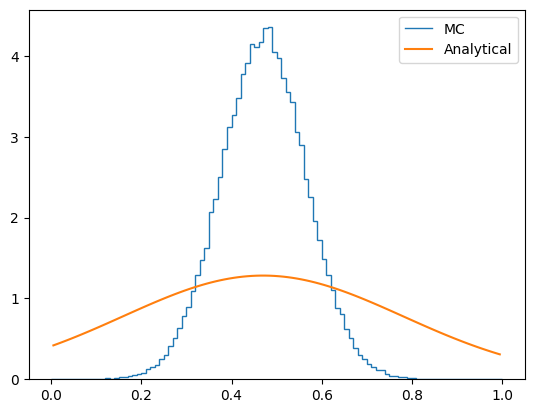

In [16]:
# plt.stairs(ion_density, x, label='BGK')
plt.stairs(density_mc, x, label='MC')
# plt.stairs(density_analytical, x, label='Analytical')
plt.plot(x_center, density_analytical, label='Analytical')
# vertical line at the split
# plt.axvline(x_split, color='r', linestyle='--')
plt.legend()
plt.show()